In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [16]:
df = pd.read_csv('/content/marketing_campaign (1).csv', sep='\t')

In [17]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [19]:
df.shape

(2240, 29)

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [21]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [22]:
df.columns = df.columns.str.strip()

df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

df.drop_duplicates(inplace=True)


In [23]:
purchase_cols = [
    'Recency', 'NumWebPurchases', 'NumCatalogPurchases',
    'NumStorePurchases', 'MntWines', 'MntFruits',
    'MntMeatProducts', 'MntFishProducts',
    'MntSweetProducts', 'MntGoldProds'
]

for col in purchase_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [24]:
print("Missing values before handling:")
print(df.isnull().sum()[df.isnull().sum() > 0])



Missing values before handling:
Income    24
dtype: int64


In [25]:
for col in df.select_dtypes(include=np.number).columns:
    if col != 'ID':
        df[col] = df[col].fillna(df[col].median())

In [26]:
for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])


In [27]:

print("\nMissing values after handling:")
print(df.isnull().sum()[df.isnull().sum() > 0])



Missing values after handling:
Series([], dtype: int64)


In [28]:
df['Frequency'] = (
    df['NumWebPurchases'] +
    df['NumCatalogPurchases'] +
    df['NumStorePurchases']
)

# Monetary = total amount spent across product categories
df['Monetary'] = (
    df['MntWines'] +
    df['MntFruits'] +
    df['MntMeatProducts'] +
    df['MntFishProducts'] +
    df['MntSweetProducts'] +
    df['MntGoldProds']
)


In [29]:
rfm = df[['Recency', 'Frequency', 'Monetary']].copy()

print(rfm.head())
print("\nRFM missing values:")
print(rfm.isnull().sum())

   Recency  Frequency  Monetary
0       58         22      1617
1       38          4        27
2       26         20       776
3       26          6        53
4       94         14       422

RFM missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64


In [30]:
scaler = StandardScaler()
X = scaler.fit_transform(rfm)

In [31]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

df['KMeans_Cluster'] = kmeans.fit_predict(X)

print(df['KMeans_Cluster'].value_counts().sort_index())


KMeans_Cluster
0    608
1    466
2    642
3    524
Name: count, dtype: int64


In [32]:
dbscan = DBSCAN(eps=0.8, min_samples=10)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X)

print(df['DBSCAN_Cluster'].value_counts().sort_index())


DBSCAN_Cluster
-1       3
 0    2237
Name: count, dtype: int64


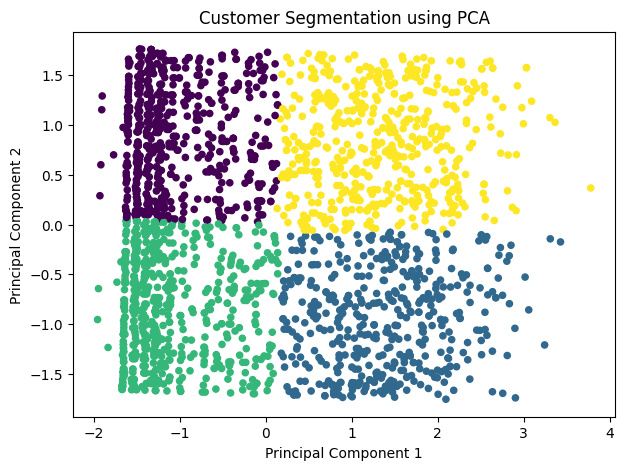

Variance explained: 0.9402688600876933


In [33]:
pca = PCA(n_components=2)
pca_data = pca.fit_transform(X)

plt.figure(figsize=(7, 5))
plt.scatter(
    pca_data[:, 0], pca_data[:, 1],
    c=df['KMeans_Cluster'], cmap='viridis', s=20
)
plt.title('Customer Segmentation using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

print("Variance explained:", pca.explained_variance_ratio_.sum())


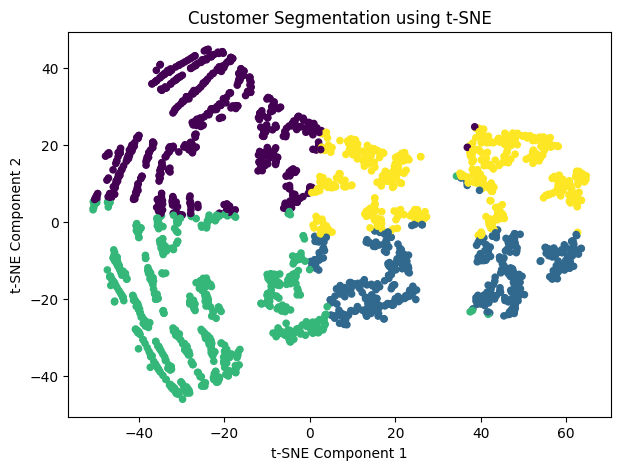

In [34]:

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init='pca',
    learning_rate='auto'
)

tsne_data = tsne.fit_transform(X)

plt.figure(figsize=(7, 5))
plt.scatter(
    tsne_data[:, 0], tsne_data[:, 1],
    c=df['KMeans_Cluster'], cmap='viridis', s=20
)
plt.title('Customer Segmentation using t-SNE')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.show()


In [35]:

personas = df.groupby('KMeans_Cluster').agg(
    Customers=('ID', 'count'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).round(2)

print(personas)

# Generate marketing recommendations
for cluster, row in personas.iterrows():
    print(f"\nCluster {cluster}:")

    if row['Avg_Recency'] > personas['Avg_Recency'].mean():
        print("Persona: At-risk customers")
        print("Action: Win-back emails and special discounts")

    elif row['Avg_Monetary'] > personas['Avg_Monetary'].mean():
        print("Persona: High-value customers")
        print("Action: Loyalty rewards and premium offers")

    elif row['Avg_Frequency'] > personas['Avg_Frequency'].mean():
        print("Persona: Frequent shoppers")
        print("Action: Membership benefits and cross-selling")

    else:
        print("Persona: Regular or developing customers")
        print("Action: Personalized recommendations and bundles")


                Customers  Avg_Recency  Avg_Frequency  Avg_Monetary
KMeans_Cluster                                                     
0                     608        74.50           7.06        148.45
1                     466        22.95          19.77       1184.53
2                     642        24.43           7.01        149.10
3                     524        73.15          19.23       1181.34

Cluster 0:
Persona: At-risk customers
Action: Win-back emails and special discounts

Cluster 1:
Persona: High-value customers
Action: Loyalty rewards and premium offers

Cluster 2:
Persona: Regular or developing customers
Action: Personalized recommendations and bundles

Cluster 3:
Persona: At-risk customers
Action: Win-back emails and special discounts
